# Figure 6.3 — control-referenced QBER comparison

Uses the saved time/QBER arrays from **C5 Visibility and QBER plots 3.ipynb**: `data[0][2][0]` and `data[0][2][1]`.

1. Set `DATA_DIR` to your processed NPY folder.
2. Review the file inventory and complete `RUNS` with matching no-emulation controls. Only filenames explicitly found in the original notebook are prefilled. Add other conditions as needed.
3. Run all cells. PDF, PNG and CSV export is optional.

No raw data were supplied with the source notebook, so numerical results cannot be precomputed here. The cached files may require your original `VisAnalysis` module to unpickle their objects. Only load trusted files.

**Interpretation:** differences are descriptive, not a correction for optical-power confounding. A fibre penalty shared by emulation and control can cancel. Missing conditions remain missing. Standard deviation describes temporal variability, not uncertainty of the mean; no confidence intervals are fabricated.

In [1]:
from pathlib import Path
import importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display
%matplotlib inline

DATA_DIR = Path(r"C:\Users\Ry\fig6.3")  # Change to your processed .npy directory
OUTPUT_DIR = Path("figure63_output")
SAVE_OUTPUTS = True
INPUT_UNITS = "fraction"  # Original notebook multiplies QBER by 100
TIME_RANGE = None  # e.g. (0, 200), in saved time coordinates
FREQUENCIES = (10, 1000)
CASE_ORDER = ["Night", "Medium", "Day","Night Slow", "Night Fast", "Night Very Fast"]

# Optional: make your original module available if saved objects require it.
# import VisAnalysis


In [3]:
# Inventory filenames only; no automatic pairing or pickle loading.
files = sorted(DATA_DIR.glob("*.npy"))
display(pd.DataFrame({"available_npy_file": [p.name for p in files]}))
if not files:
    print("No NPY files found. Set DATA_DIR before loading measurements.")


,available_npy_file
0,DF_1000_em_Numba.npy
1,DF_1000_nm_Numba.npy
2,DF_10_em_Numba.npy
3,DF_10_nm_Numba.npy
4,DNF_1000_em_Numba.npy
5,DNF_1000_nm_Numba.npy
6,DNF_100_em_Numba.npy
7,DNF_100_nm_Numba.npy
8,DNF_10_em_Numba.npy
9,DNF_10_nm_Numba.npy


In [5]:
# Automatically build RUNS from the files in DATA_DIR.
# Naming examples:
# DF_10_em_Numba.npy   = Day, fibre, 10 Hz, emulation
# DNF_10_nm_Numba.npy  = Day, no fibre, 10 Hz, no modulation

import re

PREFIX_MAP = {
    "DF":   ("Day", True),
    "DNF":  ("Day", False),
    "MF":   ("Medium", True),
    "MNF":  ("Medium", False),
    "NF":   ("Night", True),
    "NNF":  ("Night", False),

    # Wind-speed measurements: fibre-spool configuration
    "NL":   ("Night Slow", True),
    "NLF":  ("Night Fast", True),
    "NLVF": ("Night Very Fast", True),
}

TAU_BY_FREQUENCY = {
    10: 0.100,
    1000: 0.003,
}

prefix_pattern = "|".join(
    re.escape(prefix)
    for prefix in sorted(PREFIX_MAP, key=len, reverse=True)
)

pattern = re.compile(
    rf"^({prefix_pattern})_(\d+)_em_Numba\.npy$"
)

RUNS = []
missing_controls = []

for emulation_path in sorted(DATA_DIR.glob("*.npy")):
    match = pattern.fullmatch(emulation_path.name)
    if match is None:
        continue

    prefix, frequency_text = match.groups()
    frequency = int(frequency_text)

    # Figure 6.3 currently compares 10 Hz and 1000 Hz.
    if frequency not in FREQUENCIES:
        continue

    control_name = (
        f"{prefix}_{frequency}_nm_Numba.npy"
    )
    control_path = DATA_DIR / control_name

    if not control_path.is_file():
        missing_controls.append(
            f"{emulation_path.name} -> missing {control_name}"
        )
        continue

    case, fibre = PREFIX_MAP[prefix]

    RUNS.append({
        "case": case,
        "frequency": frequency,
        "fibre": fibre,
        "tau_s": TAU_BY_FREQUENCY[frequency],
        "emulation": emulation_path.name,
        "control": control_name,
    })

print(f"Found {len(RUNS)} matched emulation/control pairs.")

if RUNS:
    display(pd.DataFrame(RUNS))

if missing_controls:
    print("\nSkipped files without matching controls:")
    for message in missing_controls:
        print(" -", message)

if not RUNS:
    raise FileNotFoundError(
        f"No matching file pairs found in {DATA_DIR.resolve()}. "
        "Check DATA_DIR and the filenames."
    )

Found 18 matched emulation/control pairs.


,case,frequency,fibre,tau_s,emulation,control
0,Day,1000,True,0.003,DF_1000_em_Numba.npy,DF_1000_nm_Numba.npy
1,Day,10,True,0.100,DF_10_em_Numba.npy,DF_10_nm_Numba.npy
2,Day,1000,False,0.003,DNF_1000_em_Numba.npy,DNF_1000_nm_Numba.npy
3,Day,10,False,0.100,DNF_10_em_Numba.npy,DNF_10_nm_Numba.npy
4,Medium,1000,True,0.003,MF_1000_em_Numba.npy,MF_1000_nm_Numba.npy
5,Medium,10,True,0.100,MF_10_em_Numba.npy,MF_10_nm_Numba.npy
6,Medium,1000,False,0.003,MNF_1000_em_Numba.npy,MNF_1000_nm_Numba.npy
7,Medium,10,False,0.100,MNF_10_em_Numba.npy,MNF_10_nm_Numba.npy
8,Night,1000,True,0.003,NF_1000_em_Numba.npy,NF_1000_nm_Numba.npy
9,Night,10,True,0.100,NF_10_em_Numba.npy,NF_10_nm_Numba.npy


In [21]:
def load_qber(filename):
    path = DATA_DIR / filename
    try:
        data = np.load(path, allow_pickle=True).tolist()
    except ModuleNotFoundError as exc:
        raise RuntimeError(
            f"{path.name} contains saved Python objects. Make the original "
            "VisAnalysis module and its dependencies available."
        ) from exc
    try:
        t = np.asarray(data[0][2][0], dtype=float)
        q = np.asarray(data[0][2][1], dtype=float)
    except (IndexError, KeyError, TypeError, ValueError) as exc:
        raise ValueError(f"{path.name}: unexpected time/QBER structure") from exc
    if t.ndim != 1 or q.ndim != 1 or t.shape != q.shape:
        raise ValueError(f"{path.name}: expected matching 1-D arrays")
    mask = np.isfinite(t) & np.isfinite(q)
    if TIME_RANGE is not None:
        lo, hi = TIME_RANGE
        if lo >= hi:
            raise ValueError("TIME_RANGE must have start < end")
        mask &= (t >= lo) & (t <= hi)
    t, q = t[mask], q[mask]
    if len(q) < 2:
        raise ValueError(f"{path.name}: fewer than two valid samples")
    if np.any(np.diff(t) <= 0):
        raise ValueError(f"{path.name}: time must be strictly increasing")
    if INPUT_UNITS == "fraction":
        q = 100 * q
    elif INPUT_UNITS != "percent":
        raise ValueError("INPUT_UNITS must be fraction or percent")
    if np.any((q < 0) | (q > 100)):
        raise ValueError(f"{path.name}: QBER outside 0–100%; check units")
    return t, q


def build_summary(runs):
    rows, audit, seen = [], [], set()
    for run in runs:
        key = (run["case"], run["frequency"], run["fibre"])
        if key in seen:
            raise ValueError(f"Duplicate condition {key}; aggregate repeated runs explicitly")
        seen.add(key)
        if run["case"] not in CASE_ORDER or run["frequency"] not in FREQUENCIES:
            raise ValueError(f"Unknown case/frequency: {key}")
        if not isinstance(run["fibre"], (bool, np.bool_)) or run["tau_s"] <= 0:
            raise ValueError(f"Invalid fibre flag or tau: {key}")
        missing = [name for name in ("emulation", "control")
                   if not run.get(name) or not (DATA_DIR / run[name]).is_file()]
        if missing:
            audit.append(dict(case=key[0], frequency=key[1], fibre=key[2],
                              status="Missing: " + ", ".join(missing)))
            continue
        if (DATA_DIR/run["emulation"]).resolve() == (DATA_DIR/run["control"]).resolve():
            raise ValueError(f"Emulation and control are the same file: {key}")
        te, qe = load_qber(run["emulation"])
        tc, qc = load_qber(run["control"])
        row = dict(run)
        for label, t, q in [("emulation", te, qe), ("control", tc, qc)]:
            row.update({
                f"mean_{label}_pct": q.mean(),
                f"std_{label}_pp": q.std(ddof=0),
                f"n_{label}": len(q),
                f"start_{label}_s": t[0],
                f"end_{label}_s": t[-1],
            })
        row["delta_mean_pp"] = qe.mean() - qc.mean()
        row["delta_std_pp"] = qe.std(ddof=0) - qc.std(ddof=0)
        rows.append(row)
        audit.append(dict(case=key[0], frequency=key[1], fibre=key[2], status="Loaded"))
    summary = pd.DataFrame(rows)
    if not summary.empty:
        for frequency, group in summary.groupby("frequency"):
            if not np.allclose(group.tau_s, group.tau_s.iloc[0]):
                raise ValueError(f"Inconsistent tau values within {frequency} Hz")
    return summary, pd.DataFrame(audit)


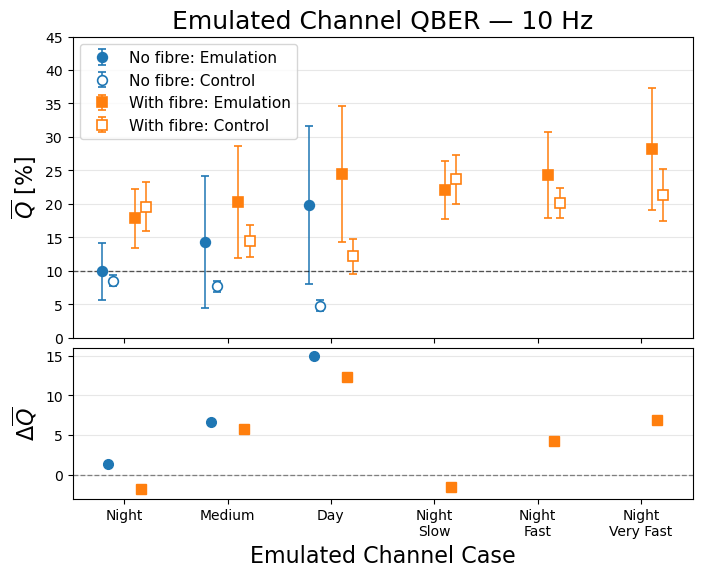

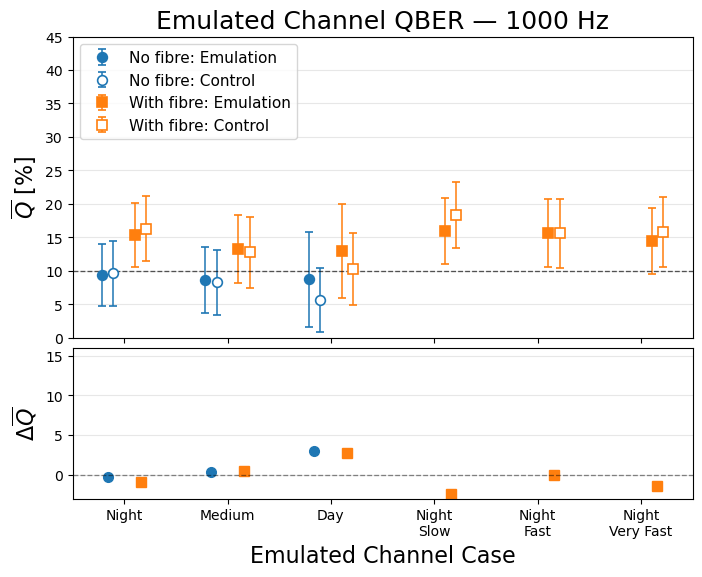

In [27]:
def plot_summary(summary):
    plt.rcParams.update({'font.size': 10})
    plt.rc('axes', titlesize=18)
    plt.rc('axes', labelsize=16)

    figures = {}
    x = np.arange(len(CASE_ORDER))
    tick_labels = [
        case.replace('Night ', 'Night\n')
        for case in CASE_ORDER
    ]

    for frequency in FREQUENCIES:
        fig, axs = plt.subplots(
            2, 1,
            sharex=True,
            gridspec_kw={'height_ratios': [2, 1]}
        )
        fig.set_size_inches(8, 6)

        subset = summary.loc[
            summary['frequency'] == frequency
        ]

        for fibre, colour, marker, label, group_offset in [
            (False, 'tab:blue', 'o', 'No fibre', -0.16),
            (True, 'tab:orange', 's', 'With fibre', 0.16),
        ]:
            group = subset.loc[subset['fibre'] == fibre]

            if group.empty:
                continue

            data = group.set_index('case').reindex(CASE_ORDER)

            # Upper panel: absolute means and distribution spread.
            for mean_col, std_col, filled, offset, condition in [
                ('mean_emulation_pct', 'std_emulation_pp',
                 True, -0.055, 'Emulation'),
                ('mean_control_pct', 'std_control_pp',
                 False, 0.055, 'Control'),
            ]:
                axs[0].errorbar(
                    x + group_offset + offset,
                    data[mean_col].to_numpy(dtype=float),
                    yerr=data[std_col].to_numpy(dtype=float),
                    linestyle='none',
                    marker=marker,
                    markersize=7,
                    markeredgewidth=1.2,
                    color=colour,
                    markerfacecolor=colour if filled else 'white',
                    capsize=3,
                    elinewidth=1.1,
                    capthick=1.1,
                    label=f'{label}: {condition}'
                )

            # Lower panel: difference between the two means.
            delta_mean = (
                data['mean_emulation_pct']
                - data['mean_control_pct']
            )

            axs[1].plot(
                x + group_offset,
                delta_mean.to_numpy(dtype=float),
                linestyle='none',
                marker=marker,
                markersize=7,
                color=colour,
                label=label
            )

        for ax in axs:
            ax.set_xlim(-0.5, len(CASE_ORDER) - 0.5)

        axs[0].set_ylim(0, 45)
        axs[1].set_ylim(-3, 16)
        # Leave upper limits automatic so error bars are not clipped.
        # Negative error-bar endpoints do not imply negative QBER.
        axs[0].tick_params(axis='x', labelbottom=False)

        axs[1].axhline(
            y=0, linestyle='--', color='k',
            alpha=0.45, linewidth=0.95
        )
        
        axs[1].set_xticks(x)
        axs[1].set_xticklabels(tick_labels)
        axs[1].set_xlabel('Emulated Channel Case')
        axs[0].grid(True, which="major",axis='y', alpha=0.3)
        axs[1].grid(True, which="major",axis='y', alpha=0.3)
        axs[0].axhline(
            y=10, linestyle='--', color='k',
            alpha=0.65, linewidth=0.95)
        axs[0].set_ylabel(r'$\overline{Q}$ [%]')
        axs[1].set_ylabel(
            r'$\Delta\overline{Q}$'
        )

        axs[0].set_title(
            f'Emulated Channel QBER — {frequency} Hz'
        )
        axs[0].legend(
            loc='upper left', fontsize=11, frameon=True
        )

        fig.subplots_adjust(hspace=0.045)
        figures[frequency] = (fig, axs)
    return figures

figures = plot_summary(summary)
plt.show()

figures[10][0].savefig('Figure_6_3_10Hz.pdf', dpi=300)
figures[1000][0].savefig('Figure_6_3_1000Hz.pdf', dpi=300)

,case,frequency,fibre,status
0,Day,1000,True,Loaded
1,Day,10,True,Loaded
2,Day,1000,False,Loaded
3,Day,10,False,Loaded
4,Medium,1000,True,Loaded
5,Medium,10,True,Loaded
6,Medium,1000,False,Loaded
7,Medium,10,False,Loaded
8,Night,1000,True,Loaded
9,Night,10,True,Loaded


,case,frequency,fibre,tau_s,emulation,control,mean_emulation_pct,std_emulation_pp,n_emulation,start_emulation_s,end_emulation_s,mean_control_pct,std_control_pp,n_control,start_control_s,end_control_s,delta_mean_pp,delta_std_pp
0,Day,1000,True,0.003,DF_1000_em_Numba.npy,DF_1000_nm_Numba.npy,12.944180,6.993377,4762,0.0015,199.9635,10.261610,5.397792,4762,0.0015,199.9635,2.682570,1.595585
1,Day,10,True,0.100,DF_10_em_Numba.npy,DF_10_nm_Numba.npy,24.504264,10.174650,2000,0.0500,199.9500,12.139576,2.590525,2000,0.0500,199.9500,12.364688,7.584125
2,Day,1000,False,0.003,DNF_1000_em_Numba.npy,DNF_1000_nm_Numba.npy,8.706117,7.057608,4762,0.0015,199.9635,5.666836,4.763466,4762,0.0015,199.9635,3.039281,2.294142
3,Day,10,False,0.100,DNF_10_em_Numba.npy,DNF_10_nm_Numba.npy,19.762703,11.800882,2000,0.0500,199.9500,4.812184,0.890210,2000,0.0500,199.9500,14.950519,10.910673
4,Medium,1000,True,0.003,MF_1000_em_Numba.npy,MF_1000_nm_Numba.npy,13.294438,5.091449,4762,0.0015,199.9635,12.767248,5.265130,4762,0.0015,199.9635,0.527191,-0.173681
5,Medium,10,True,0.100,MF_10_em_Numba.npy,MF_10_nm_Numba.npy,20.276185,8.429304,2000,0.0500,199.9500,14.443909,2.362232,2000,0.0500,199.9500,5.832276,6.067072
6,Medium,1000,False,0.003,MNF_1000_em_Numba.npy,MNF_1000_nm_Numba.npy,8.638237,4.969178,4762,0.0015,199.9635,8.319057,4.861585,4762,0.0015,199.9635,0.319180,0.107592
7,Medium,10,False,0.100,MNF_10_em_Numba.npy,MNF_10_nm_Numba.npy,14.336845,9.873487,2000,0.0500,199.9500,7.684086,0.848762,2000,0.0500,199.9500,6.652759,9.024725
8,Night,1000,True,0.003,NF_1000_em_Numba.npy,NF_1000_nm_Numba.npy,15.400255,4.779210,4762,0.0015,199.9635,16.316725,4.887746,4762,0.0015,199.9635,-0.916470,-0.108536
9,Night,10,True,0.100,NF_10_em_Numba.npy,NF_10_nm_Numba.npy,17.859603,4.408846,2000,0.0500,199.9500,19.603819,3.627362,2000,0.0500,199.9500,-1.744217,0.781484


C:\Users\Ry\AppData\Local\Temp\ipykernel_41372\3961535326.py:89: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[1].set_xticklabels(tick_labels)
C:\Users\Ry\AppData\Local\Temp\ipykernel_41372\3961535326.py:89: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[1].set_xticklabels(tick_labels)


AttributeError: 'int' object has no attribute 'savefig'

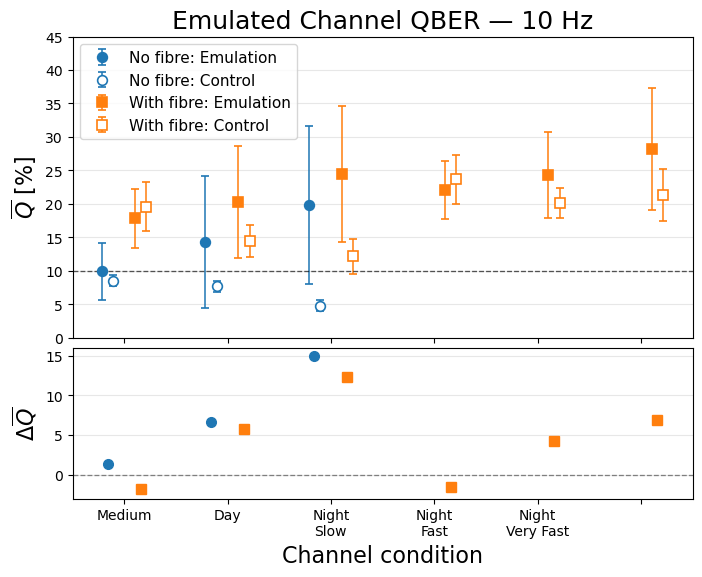

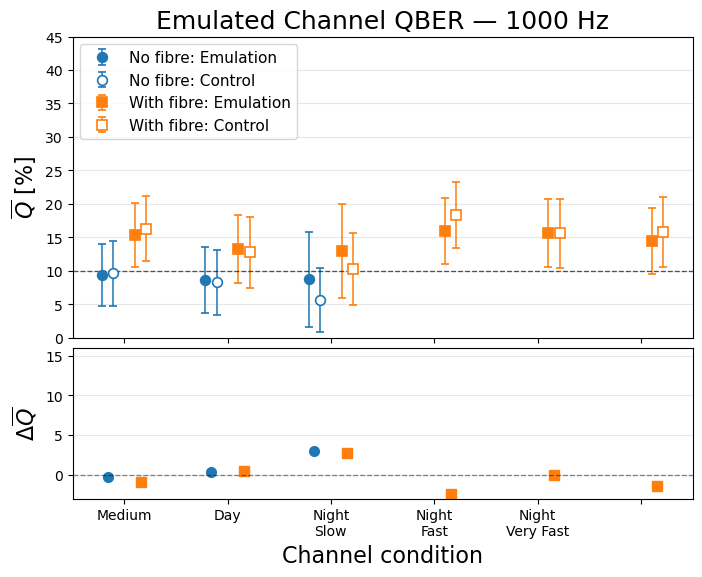

In [17]:
summary, audit = build_summary(RUNS)
display(audit)
if summary.empty:
    print("No complete pairs. Fill in control filenames and check DATA_DIR.")
else:
    display(summary)
    fig63, axes63 = plot_summary(summary)
    if SAVE_OUTPUTS:
        OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
        stem = OUTPUT_DIR / "Figure_6_3"
        fig63.savefig(stem.with_suffix(".pdf"), bbox_inches="tight")
        fig63.savefig(stem.with_suffix(".png"), dpi=300, bbox_inches="tight")
        summary.to_csv(OUTPUT_DIR / "Figure_6_3_statistics.csv", index=False)
        audit.to_csv(OUTPUT_DIR / "Figure_6_3_input_audit.csv", index=False)
        print(f"Saved outputs to {OUTPUT_DIR.resolve()}")
    plt.show()


In [15]:
figures = plot_summary(summary)
plt.show()

if SAVE_OUTPUTS:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

    for frequency, (fig, axs) in figures.items():
        stem = OUTPUT_DIR / f"Figure_6_3_{frequency}Hz"

        fig.savefig(stem.with_suffix(".pdf"), bbox_inches="tight")
        fig.savefig(
            stem.with_suffix(".png"),
            dpi=300,
            bbox_inches="tight"
        )

    summary.to_csv(
        OUTPUT_DIR / "Figure_6_3_statistics.csv",
        index=False
    )

NameError: name 'summary' is not defined

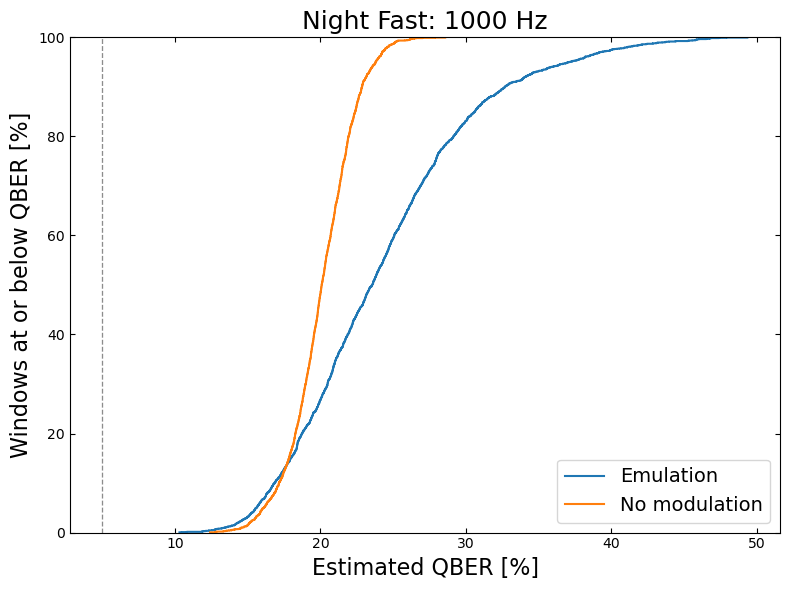

Emulation: 0.0% of windows at or below 5% QBER; 90th-percentile QBER = 32.68%
No modulation: 0.0% of windows at or below 5% QBER; 90th-percentile QBER = 22.86%


In [160]:
def load_qber_percent(filename):
    # Only load trusted files: these arrays contain pickled objects.
    data = np.load(filename, allow_pickle=True).tolist()
    qber = np.asarray(data[0][2][1], dtype=float).ravel()

    # Saved QBER is assumed to be a fraction.
    return 100 * qber[np.isfinite(qber)]


q_em = load_qber_percent(DATA_DIR / 'NLF_10_em_Numba.npy')
q_nm = load_qber_percent(DATA_DIR / 'NLF_10_nm_Numba.npy')

plt.rcParams.update({'font.size': 10})
plt.rc('axes', titlesize=18)
plt.rc('axes', labelsize=16)

fig, ax = plt.subplots(figsize=(8, 6))

for q, colour, label in [
    (q_em, 'tab:blue', 'Emulation'),
    (q_nm, 'tab:orange', 'No modulation'),
]:
    if q.size == 0:
        raise ValueError(f'No finite QBER estimates for {label}.')

    q_sorted = np.sort(q)
    cumulative_percent = (
        100 * np.arange(1, q_sorted.size + 1) / q_sorted.size
    )

    ax.step(
        q_sorted, cumulative_percent,
        where='post', color=colour, label=label
    )

# Illustrative comparison threshold, not a security threshold.
q_threshold = 5.0

ax.axvline(
    q_threshold, linestyle='--', color='k',
    alpha=0.45, linewidth=0.95
)

ax.set_xlabel('Estimated QBER [%]')
ax.set_ylabel('Windows at or below QBER [%]')
ax.set_title('Night Fast: 1000 Hz')
ax.set_ylim(0, 100)
ax.tick_params(direction='in', top=True, right=True)
ax.legend(loc='lower right', fontsize=14, frameon=True)

fig.tight_layout()
plt.show()

for label, q in [('Emulation', q_em), ('No modulation', q_nm)]:
    below = 100 * np.mean(q <= q_threshold)
    q90 = np.percentile(q, 90)

    print(
        f'{label}: {below:.1f}% of windows at or below '
        f'{q_threshold:g}% QBER; '
        f'90th-percentile QBER = {q90:.2f}%'
    )

# fig.savefig('QBER_Cumulative_Distribution.pdf', bbox_inches='tight')

## Caption and interpretation

**Figure 6.3.** Changes in the mean (upper panels) and standard deviation (lower panels) of time-resolved estimated QBER relative to the corresponding no-emulation control. Columns distinguish phase-reference repetition rates; analysis intervals are stated in the panel headings. Filled circles indicate no fibre spools, and open squares indicate the fibre-spool configuration. Positive values denote an increase relative to control. Standard deviations are calculated with `ddof=0`, matching the original histogram code. Missing measurements are not interpolated. No confidence intervals are shown.

The differences compare distributions, not pointwise paired time samples. They do not remove differences in mean optical power or run-to-run drift. Compare the absolute means exported in the CSV when discussing the overall fibre penalty. Different averaging times also affect the measured spread, so cross-frequency comparisons include both reference-rate and analysis-window effects.

The prefilled `tau_s` values follow the thesis settings; verify them against the code that generated each cache. Time-series spacing may be a sliding-window stride and cannot confirm the window duration. Do not treat a 10% optical-error threshold as a universal TF-QKD security limit.